# PCA and LDA: What Does Reduction Preserve?
## Variance, class separation, and the cost of fewer dimensions

**Practical 8 — core approximately 65–70 minutes, optional extension up to 85 minutes**

In Practical 6–7, we turned structured objects into numerical features. Now we have the opposite problem:
**what if there are too many features to inspect or plot directly?**

We will compare two linear methods:

- **PCA** looks for directions that retain as much overall variance as possible. It does not use class labels.
- **LDA (Linear Discriminant Analysis)** uses class labels to find directions that separate class centres relative to within-class variation.

Both produce lower-dimensional coordinates, but they preserve **different kinds of information**.

> A useful two-dimensional plot is not proof that we preserved everything important.

### Learning outcomes

After this session you should be able to:

1. describe a data matrix as observations × features
2. explain why centering and scaling affect PCA
3. read PCA scores, components, and explained variance ratios
4. project and approximately reconstruct observations using PCA
5. explain why PCA does not optimize class separation
6. explain how LDA uses labels and why its dimension is at most *number of classes − 1*
7. compare PCA and LDA without treating their axes as interchangeable
8. fit preprocessing on training data only when evaluating on held-out observations

### Requirements

`numpy`, `pandas`, `matplotlib`, `scikit-learn`.

The real UCI Wine dataset is bundled with `scikit-learn`; no downloads or auxiliary files are required.

### Session plan

| Time | Part | Main question |
|---|---|---|
| 0–10 min | 1. Dataset | What are we reducing, and what do the labels mean? |
| 10–20 min | 2. Scaling | Why can units change PCA directions? |
| 20–45 min | 3. PCA | How much variance do we keep, and what do we lose? |
| 45–60 min | 4. LDA | What changes when labels define the objective? |
| 60–70 min | 5. Exit challenge | Choose and defend a representation |
| 70–85 min | 6. Optional | A counterexample and held-out evaluation |

The **core is Parts 1–5**. Optional work is at the end, not required to finish the main story.

---
## 0. Environment

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import __version__ as sklearn_version
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

print('Python:      ', sys.version.split()[0])
print('NumPy:       ', np.__version__)
print('pandas:      ', pd.__version__)
print('scikit-learn:', sklearn_version)

Python:       3.13.5
NumPy:        2.3.5
pandas:       2.2.3
scikit-learn: 1.8.0


---
## 1. A real dataset with multiple measured features

We use the **Wine** dataset from the UCI Machine Learning Repository, available through
`sklearn.datasets.load_wine`.

- **178** wine samples
- **13** numerical chemical measurements
- **3** classes representing different *grape cultivars*, not wine quality ratings

**Source:** [UCI Wine dataset](https://archive.ics.uci.edu/dataset/109/wine)  
**Convenient offline loader:** [scikit-learn `load_wine`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html)

These observations came from chemical analyses of wines from the same Italian region. Do not assume
that the sample represents all wines, regions, or years.

Our goal is to move from a **13-dimensional feature space** to a space we can visualize, and to
understand what that change preserves.

In [2]:
wine = load_wine(as_frame=True)
X = wine.data.copy()
y = wine.target.copy().rename('cultivar')

print('X shape:', X.shape)
print('Class counts:')
print(y.value_counts().sort_index())

display(X.head())

X shape: (178, 13)
Class counts:
cultivar
0    59
1    71
2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


`X` contains measurements. `y` contains class labels. They play **different roles**:

- PCA must not use `y` when fitting its directions.
- LDA must use `y` because class separation is its objective.

Before fitting anything, verify that there are no missing values in the copy supplied by `scikit-learn`.

In [3]:
print('Missing feature values:', int(X.isna().sum().sum()))
print('Feature count:', X.shape[1])

assert X.shape[0] == len(y)
assert X.select_dtypes(include='number').shape[1] == X.shape[1]
assert not X.isna().any().any()

Missing feature values: 0
Feature count: 13


### Keep a separate evaluation set

Even though this is mostly an exploratory lesson, we will reserve a test set now. That way, the
optional evaluation at the end does not accidentally learn from the answers it is supposed to test.

Fit means, scales, PCA axes, and LDA directions **on training data only**.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print('Training:', X_train.shape, '| Test:', X_test.shape)

Training: (133, 13) | Test: (45, 13)


---
## 2. Scaling changes the geometry

PCA operates on Euclidean variation. Its result depends on the units and scales of the columns.

For example, a feature measured in hundreds can have far more raw variance than a feature measured
in tenths. That does not automatically mean it is more informative.

Let's look at the measured spreads before deciding how to scale.

In [5]:
spreads = (
    X_train.std()
    .sort_values(ascending=False)
    .rename('standard_deviation')
    .to_frame()
)

display(spreads.head(6))
display(spreads.tail(4))

,standard_deviation
proline,304.904854
magnesium,14.982313
alcalinity_of_ash,3.366389
color_intensity,2.365661
malic_acid,1.090271
flavanoids,0.958150


,standard_deviation
proanthocyanins,0.585901
ash,0.266693
hue,0.225866
nonflavanoid_phenols,0.118534


Two legitimate, but different, choices are:

**Covariance PCA:** centre features, retaining their original relative scales.  
**Correlation-style PCA:** standardize features to approximately zero mean and unit variance first.

Neither is universally correct. Standardization is useful here because measurements have different
ranges and units, but it also changes the meaning of distance.

In [6]:
# Compare a raw-scale PCA with one fitted after standardization.
raw_pca = PCA(n_components=2).fit(X_train)

scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

scaled_pca = PCA(n_components=2).fit(X_train_scaled)

comparison = pd.DataFrame({
    'raw scale': raw_pca.explained_variance_ratio_,
    'standardized': scaled_pca.explained_variance_ratio_,
}, index=['PC1', 'PC2'])

display(comparison.round(3))

print('Largest absolute loading of raw PC1:')
print(pd.Series(raw_pca.components_[0], index=X.columns).abs().sort_values(ascending=False).head(3))

,raw scale,standardized
PC1,0.998,0.357
PC2,0.002,0.192


Largest absolute loading of raw PC1:
proline              0.999785
magnesium            0.019774
alcalinity_of_ash    0.005100
dtype: float64


The percentages differ because the geometry differs. We are not just “cleaning” the data — we
are defining which differences matter.

For the rest of this notebook we will use **standardized features**, with the scaler fitted only on
`X_train`.

---
## 3. PCA — keep directions of high variance

Given centred observations in a matrix \(X_c\in\mathbb R^{n\times d}\), PCA seeks orthogonal
axes along which the sample varies most.

A principal direction \(v\) solves

\[
\max_{\|v\|_2=1} v^\top S v,
\qquad S=\frac{1}{n-1}X_c^\top X_c.
\]

The lecture derives the eigenvector/SVD connection. Here we focus on what the computation produces
and what it means.

In [7]:
pca_full = PCA().fit(X_train_scaled)

explained = pd.DataFrame({
    'component': np.arange(1, len(pca_full.explained_variance_ratio_) + 1),
    'explained_variance_ratio': pca_full.explained_variance_ratio_,
    'cumulative_ratio': np.cumsum(pca_full.explained_variance_ratio_),
})

display(explained.head(8).round(3))

,component,explained_variance_ratio,cumulative_ratio
0,1,0.357,0.357
1,2,0.192,0.550
2,3,0.108,0.658
3,4,0.074,0.732
4,5,0.069,0.802
5,6,0.052,0.854
6,7,0.044,0.898
7,8,0.025,0.923


### 3.1 How many components should we keep?

The **explained variance ratio** tells us what fraction of total *standardized training-set variance*
is accounted for by each PCA direction.

A threshold such as 90% is a useful compression rule, **not** a guarantee of predictive accuracy.

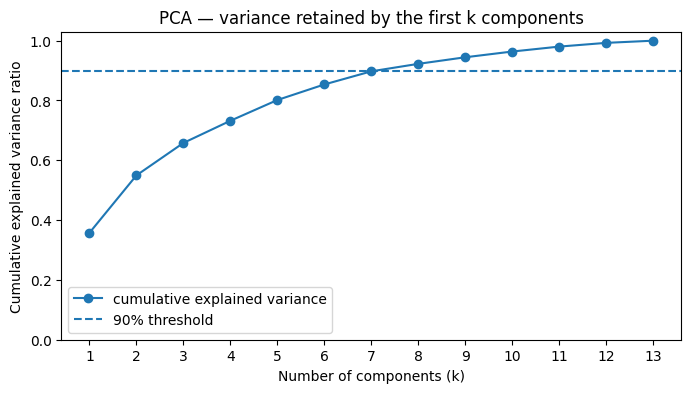

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    explained['component'],
    explained['cumulative_ratio'],
    marker='o',
    label='cumulative explained variance',
)
ax.axhline(0.90, linestyle='--', label='90% threshold')
ax.set(
    title='PCA — variance retained by the first k components',
    xlabel='Number of components (k)',
    ylabel='Cumulative explained variance ratio',
    xticks=explained['component'],
    ylim=(0, 1.03),
)
ax.legend()
plt.show()

In [9]:
threshold = 0.90
k90 = int(np.searchsorted(explained['cumulative_ratio'].to_numpy(), threshold) + 1)

print(f'Smallest k retaining at least {threshold:.0%} of standardized variance: {k90}')
print(f'Two components retain {explained.loc[1, "cumulative_ratio"]:.1%} of standardized variance')

Smallest k retaining at least 90% of standardized variance: 8
Two components retain 55.0% of standardized variance


### 3.2 PCA scores are new coordinates

Let the columns of \(V_2\) be the first two principal directions. The two-dimensional scores are

\[
Z = X_c V_2.
\]

This is a **linear projection** of the original measurements.

The plot will be coloured by the class labels **after** fitting PCA. Colouring points does not make
PCA supervised.

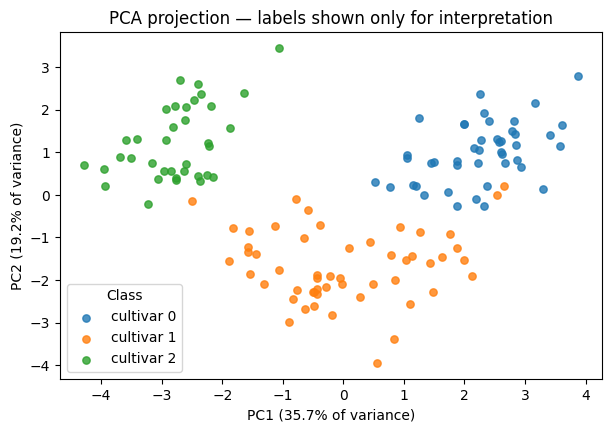

In [10]:
pca_2 = PCA(n_components=2).fit(X_train_scaled)
Z_pca_train = pca_2.transform(X_train_scaled)
Z_pca_test = pca_2.transform(X_test_scaled)

fig, ax = plt.subplots(figsize=(7, 4.5))
for cls in np.sort(y_train.unique()):
    mask = y_train.to_numpy() == cls
    ax.scatter(
        Z_pca_train[mask, 0], Z_pca_train[mask, 1],
        label=f'cultivar {cls}', alpha=0.8, s=28,
    )

ax.set(
    title='PCA projection — labels shown only for interpretation',
    xlabel=f'PC1 ({pca_2.explained_variance_ratio_[0]:.1%} of variance)',
    ylabel=f'PC2 ({pca_2.explained_variance_ratio_[1]:.1%} of variance)',
)
ax.legend(title='Class')
plt.show()

### 3.3 Components tell us how features combine

`components_[j, i]` is the coefficient of original **standardized feature** `i` in principal
component `j`.

Large absolute coefficients indicate influential coordinates *for that direction*. The signs of
PCA axes can flip without changing the mathematical result.

In [11]:
loadings = pd.DataFrame(
    pca_2.components_.T,
    index=X.columns,
    columns=['PC1', 'PC2'],
)

print('Features with largest absolute PC1 coefficients:')
display(loadings.reindex(loadings['PC1'].abs().sort_values(ascending=False).index).head(6).round(3))

Features with largest absolute PC1 coefficients:


,PC1,PC2
flavanoids,0.428,-0.002
total_phenols,0.393,0.070
od280/od315_of_diluted_wines,0.382,-0.171
proanthocyanins,0.311,0.003
hue,0.304,-0.287
proline,0.291,0.368


### 3.4 Projection is lossy — reconstruction shows what was removed

PCA can approximately reconstruct an observation from its reduced coordinates:

\[
\hat X_c=ZV_k^\top.
\]

Keeping fewer components usually increases squared reconstruction error. It does not necessarily
remove only task-irrelevant information.

In [12]:
X_approx_2 = pca_2.inverse_transform(Z_pca_train)

mse_2 = np.mean((X_train_scaled - X_approx_2) ** 2)

pca_90 = PCA(n_components=k90).fit(X_train_scaled)
Z_90 = pca_90.transform(X_train_scaled)
X_approx_90 = pca_90.inverse_transform(Z_90)
mse_90 = np.mean((X_train_scaled - X_approx_90) ** 2)

print(f'Mean squared reconstruction error, k=2:   {mse_2:.3f}')
print(f'Mean squared reconstruction error, k={k90}: {mse_90:.3f}')
print('Errors are measured in standardized-feature units squared.')

Mean squared reconstruction error, k=2:   0.450
Mean squared reconstruction error, k=8: 0.077
Errors are measured in standardized-feature units squared.


### Exercise A — a different compression target

Repeat the component-count and reconstruction check for **95% cumulative explained variance**.

Report:

1. the smallest number of components meeting the threshold
2. the corresponding mean squared reconstruction error
3. one sentence: what does the 95% threshold guarantee, and what does it *not* guarantee?

Use the already-fitted scaler. Do not fit a new scaler on `X_test`.

In [13]:
# Your solution starts here.

---
## 4. LDA — use labels to separate classes

**LDA here means Linear Discriminant Analysis**, not *Latent Dirichlet Allocation* from topic
modelling.

PCA uses total variance. Fisher LDA instead seeks directions where class means are far apart
relative to within-class scatter:

\[
J(w)=\frac{w^\top S_B w}{w^\top S_W w}.
\]

- \(S_B\) measures **between-class** scatter.
- \(S_W\) measures **within-class** scatter.

The method uses the training labels `y_train`. For \(C\) classes it has at most
\(C-1\) nonzero discriminant axes. With three cultivars, we can display at most **two**.

In [14]:
num_classes = y_train.nunique()
lda_components = min(2, num_classes - 1)

lda = LinearDiscriminantAnalysis(n_components=lda_components)
Z_lda_train = lda.fit_transform(X_train_scaled, y_train)
Z_lda_test = lda.transform(X_test_scaled)

print('Classes:', num_classes)
print('Maximum number of LDA axes:', num_classes - 1)
print('LDA projection shape:', Z_lda_train.shape)

Classes: 3
Maximum number of LDA axes: 2
LDA projection shape: (133, 2)


### Compare the two projections on the same training observations

Here the horizontal and vertical axes do **not** have the same numerical meaning across panels.
The point of the comparison is the pattern of **within- and between-class structure**, not the absolute
coordinate ranges or the visual spacing induced by automatic plot limits.

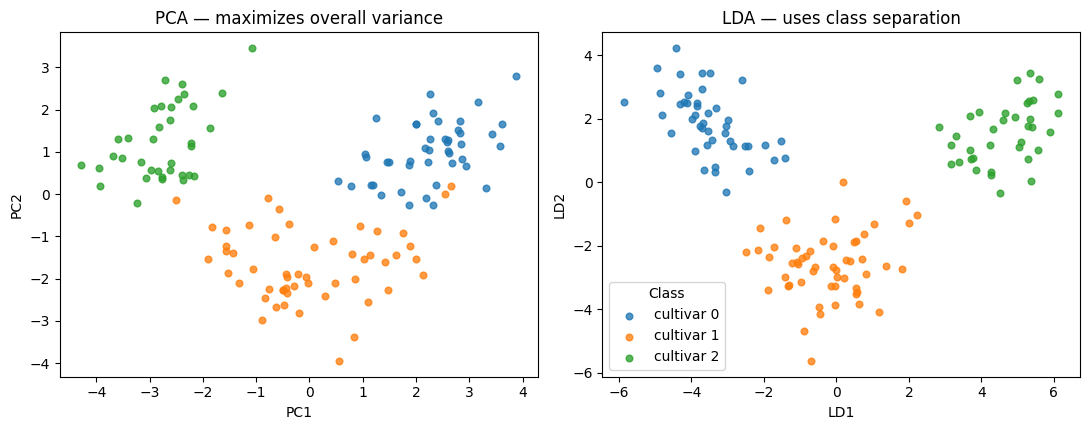

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

for ax, Z, title, names in [
    (axes[0], Z_pca_train, 'PCA — maximizes overall variance', ('PC1', 'PC2')),
    (axes[1], Z_lda_train, 'LDA — uses class separation', ('LD1', 'LD2')),
]:
    for cls in np.sort(y_train.unique()):
        mask = y_train.to_numpy() == cls
        ax.scatter(Z[mask, 0], Z[mask, 1], label=f'cultivar {cls}', s=23, alpha=0.78)
    ax.set(title=title, xlabel=names[0], ylabel=names[1])

axes[1].legend(title='Class')
plt.tight_layout()
plt.show()

The two methods answer different questions:

| | PCA | Fisher LDA |
|---|---|---|
| Uses labels during fitting? | No | Yes |
| Optimizes | Total variance | Between-class separation relative to within-class variation |
| Maximum meaningful axes | At most `min(n_train − 1, d)` | At most `min(d, C − 1)` |
| Natural interpretation | Compression / reconstruction | Supervised class-discriminating coordinates |

**Important:** `lda.explained_variance_ratio_`, if available, summarizes relative *discriminant*
information among LDA axes. It is **not** the same quantity as PCA's fraction of original total
variance. Do not place those ratios on one chart as though they shared a denominator.

### Exercise B — compare the objectives

Use the two plots above and the fitted models to answer in Markdown:

1. Which method was fitted **without** the cultivar labels?
2. Why does LDA produce at most two axes here even though we started with 13 features?
3. Does a visually separated PCA plot imply that PCA optimized class separation?

**Answer here:**

*Replace this sentence with your explanation.*

---
## 5. Exit challenge — choose a reduction for a purpose

Consider two goals:

**Goal A:** keep as much standardized chemical-measurement variance as possible, using fewer
than 13 coordinates.  
**Goal B:** find a small set of coordinates that separates the three known cultivars.

Use the results from this notebook and write a short response covering:

1. which method you would try first for each goal, and why
2. how many PCA components met the **90%** threshold on the training data
3. why using **all** labels to fit LDA before train/test splitting would make a later test misleading
4. one important piece of information that a two-dimensional projection may hide

Do not claim that one method is universally better. There is no single best reduced space for every task.

**Your response:**

*Replace this text with four short answers.*

---
## 6. Optional extension — when variance is the wrong goal

Skip this section if the core practical has filled the available class time.

### 6.1 A controlled counterexample

The real Wine data can show clear class patterns under PCA, but that does not mean PCA uses labels.
Here is a **synthetic teaching example** designed to separate the objectives:

- the first coordinate varies widely and mostly independently of class
- the second coordinate varies less but distinguishes two classes

PCA should favour the first direction. LDA can favour the second.

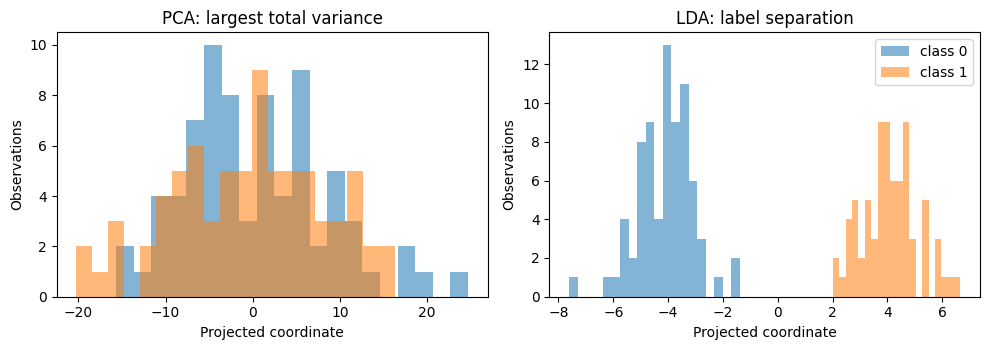

In [16]:
rng = np.random.default_rng(2026)
n = 150
labels = np.repeat([0, 1], n // 2)

# Broad horizontal nuisance variation; narrow vertical class signal.
noise_axis = rng.normal(loc=0, scale=8.0, size=n)
signal_axis = (labels * 2 - 1) * 1.5 + rng.normal(0, 0.35, n)
X_toy = np.column_stack([noise_axis, signal_axis])

toy_pca = PCA(n_components=1).fit(X_toy)
toy_lda = LinearDiscriminantAnalysis(n_components=1).fit(X_toy, labels)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, z, title in [
    (axes[0], toy_pca.transform(X_toy)[:, 0], 'PCA: largest total variance'),
    (axes[1], toy_lda.transform(X_toy)[:, 0], 'LDA: label separation'),
]:
    for cls in [0, 1]:
        ax.hist(z[labels == cls], bins=20, alpha=0.55, label=f'class {cls}')
    ax.set(title=title, xlabel='Projected coordinate', ylabel='Observations')

axes[1].legend()
plt.tight_layout()
plt.show()

This example is deliberately constructed, unlike the Wine observations. It does **not** show that
LDA always works better; it shows why **variance and class information are different objectives**.

### 6.2 Evaluate a representation on held-out data

A plot is not a performance metric. To illustrate that, fit the **same** simple classifier on the
two-dimensional PCA scores and on the two-dimensional LDA scores, using only training data.

The test set is used only to report the result. This is one split of a small dataset, **not** a robust
benchmark or a licence to choose hyperparameters based on test accuracy.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

scores = {}

for name, train_features, test_features in [
    ('PCA (2D)', Z_pca_train, Z_pca_test),
    ('LDA (2D)', Z_lda_train, Z_lda_test),
]:
    model = LogisticRegression(max_iter=2000)
    model.fit(train_features, y_train)
    prediction = model.predict(test_features)
    scores[name] = accuracy_score(y_test, prediction)

print(pd.Series(scores, name='held_out_accuracy').round(3))

PCA (2D)    0.911
LDA (2D)    0.978
Name: held_out_accuracy, dtype: float64


Notice that LDA already used class labels when constructing the representation. That is allowed
**inside the training set**. It would not be allowed to fit the discriminant directions using the
held-out labels before reporting held-out performance.

If you were actually choosing a pipeline for deployment, you would validate it across repeated
splits or cross-validation folds, with preprocessing and reduction fitted separately inside each fold.

---
## Summary

### 1. PCA preserves a chosen notion of variance

It finds orthogonal directions with large variation and supports approximate reconstruction.
It does not know the class labels.

### 2. Scaling is a modelling choice

PCA directions depend on feature scale. Standardization is often sensible for different units, but
changes the geometry and can amplify noisy low-variance features.

### 3. LDA preserves a different kind of structure

It uses training labels and seeks class-discriminating directions. With \(C\) classes, there are at
most \(C-1\) discriminant dimensions.

### 4. Two dimensions are not the whole dataset

A score plot can hide class overlap, rare patterns and information in omitted components.
Choose the representation for the task, not because one plot looks prettier.

**Next:** clustering, where the geometry created by representation and scaling will influence which
observations appear close together.

### Further reading

- [UCI: Wine dataset](https://archive.ics.uci.edu/dataset/109/wine)
- [scikit-learn: PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
- [scikit-learn: LinearDiscriminantAnalysis](https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.LinearDiscriminantAnalysis.html)
- [scikit-learn: pitfalls and data leakage](https://scikit-learn.org/stable/common_pitfalls.html)